# Step 8 – Penetration depth from interferometric volume decorrelation

The radar wave penetrates into snow and firn and is scattered over a range of depths. Because the two acquisitions of a pair look at the scene from slightly different angles, this vertical spread lowers the coherence: the deeper the penetration, the lower the coherence, and the more so the larger the baseline. Following **Hoen & Zebker (2000)**, *Penetration depths inferred from interferometric volume decorrelation observed over the Greenland Ice Sheet*, IEEE TGRS 38(6), the coherence of step 7 is inverted into a penetration depth for every pixel and polarisation.

**Model.** The coherence of a pair is a product of factors (eq. 17, 13):

$$\rho = \rho_{surface}\cdot\rho_{volume}\cdot\rho_{temporal}$$

written here with the vertical wavenumber $k_z$ of each pair, which BIOMASS gives in the LUT (`coregistration_waveNumbers`), instead of the baseline $B_\perp$ ($k_z = 4\pi B_\perp / (\lambda r_0 \sin\theta)$):

| Factor | Equation | Meaning |
|---|---|---|
| surface (eq. 14) | $\rho_{surface} = 1 - \dfrac{\lvert k_z\rvert\, R_r \cos\theta}{2\pi}$ | decorrelation from the different viewing angles, even without penetration ($R_r$ = slant range resolution) |
| volume (eq. 16) | $\rho_{volume} = \dfrac{1}{\sqrt{1 + \left(\lvert k_z\rvert \sqrt{\varepsilon}\cos\theta\; d/2\right)^2}}$ | decorrelation from scattering spread over depth; $d$ = penetration depth (one-way, 1/e of the power), $\varepsilon$ = permittivity of the firn |
| temporal (eq. 18) | $\rho_{temporal} = a_t + s_t\, t$ | changes in the snow between the acquisitions ($t$ = days between them) |

The volume factor assumes a homogeneous firn in which the backscatter decreases exponentially with depth (eq. 15). With 6 pairs per polarisation that have different $k_z$ and different $t$, $d$, $a_t$ and $s_t$ are fitted together by least squares for every pixel (eq. 19).

**Density and temperature.** The firn permittivity follows from the density: $\varepsilon = (1 + 0.845\,\rho)^2$ (Kovacs et al. 1995, ρ in g/cm³). Since the model only contains $\sqrt{\varepsilon}\,d$, a higher density gives exactly a proportionally smaller $d$: $d \propto 1/\sqrt{\varepsilon}$. Temperature is not part of the Hoen & Zebker model. It sets the absorption of ice, so the measured $d$ is compared with the **absorption-only depth** $\lambda\sqrt{\varepsilon'}/(2\pi\varepsilon'')$, with $\varepsilon''$ of ice from Mätzler (2006) and of firn from Tiuri et al. (1984). This depth ignores scattering losses and is therefore an upper limit: if the measured $d$ is much smaller, scattering, not absorption, limits the penetration.

**Limitations.** Thermal noise (SNR) is not included, which matters most for the weaker HV/VH channels: low SNR also lowers the coherence and is then read as a deeper penetration. Residual ionospheric effects at P-band are not modelled either. Pixels where $d$ reaches `D_MAX_M` mean "at least this deep, or no volume information".

**Outputs per stack** (in `<run folder>/<stack folder>/penetration/`):
- `<stack>_penetration.png`: map of $d$ per polarisation
- `<stack>_coherence_fit.png`: median coherence of every pair versus $\lvert k_z\rvert$ with the fitted model (as Fig. 4 of the paper)
- `<stack>_sensitivity.png`: (a) $d$ versus density, (b) $d$ with and without the surface and temporal factors, (c) absorption-only depth versus temperature compared with the measured $d$
- `<stack>_<pol>_penetration.tif`: 5 bands: $d$, $a_t$, $s_t$, rmse of the fit, number of pairs used
- `<stack>_penetration_summary.csv`: all numbers of the figures

**How to use**
0. First time only: run **8.0** to install the packages, then restart the kernel.
1. Set `DATA_DIR` and `OUTPUT_DIR` in **8.1**, then run **8.1** and **8.2**. The input data are needed for $k_z$ and the incidence angle in the LUT.
2. Fill in **8.3 Settings**, with `RUN_07_DIR = "latest"` the newest step 7 results in `OUTPUT_DIR` are used, so set the same `OUTPUT_DIR` in 8.1 as in step 7 (run step 7 with `PHASE_CORRECTION = "flattening"` or `"flattening+calibration"`).
3. Run **8.4**.

`BiomassProduct.py` (ESA) and `polsar_utils.py` must be in the same folder as this notebook.

## 8.0 First time only: install the packages
Run once, then restart the kernel (**Kernel → Restart Kernel**). `--user` installs them in your home folder, so they are kept when the server restarts. Skip this cell if 8.1 runs without errors.

In [1]:
%pip install --user netCDF4 xarray folium shapely pillow

Note: you may need to restart the kernel to use updated packages.


## 8.1 Load the tools and choose the folders
- `DATA_DIR`: the folder that contains your stacks. It can be a folder on your computer or a cloud bucket mounted as a folder. Leave it as `None` to search automatically.
- `OUTPUT_DIR`: the main folder for all results. It is created if it does not exist; `~` is your home folder.

In [1]:
%matplotlib inline
import polsar_utils as pu

DATA_DIR = "/home/jovyan/shared-buckets/6e08893c-463e-498b-92d2-6761dd17160d/biomass_inputs"
OUTPUT_DIR = "/home/jovyan/idas_dump/test/Nivlisen"

## 8.2 Overview of the data

In [2]:
stacks = pu.find_stacks(DATA_DIR)
pu.print_overview(stacks)

8 stack(s), 55 scene(s)

[0] BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS  (6 scenes)
      [0] 2026-07-04 16:11             BIO_S1_STA__1S_20260704T161134_20260704T161157_T_G01_M04_C01_T010_F217_02_DV88YC
      [1] 2026-07-07 16:11             BIO_S1_STA__1S_20260707T161136_20260707T161159_T_G01_M04_C02_T010_F217_02_DV88Z2
      [2] 2026-07-10 16:11             BIO_S1_STA__1S_20260710T161138_20260710T161201_T_G01_M04_C03_T010_F217_02_DV88ZR
      [3] 2026-07-13 16:11  ★ primary  BIO_S1_STA__1S_20260713T161140_20260713T161203_T_G01_M04_C04_T010_F217_02_DV890B
      [4] 2026-07-19 16:11             BIO_S1_STA__1S_20260719T161143_20260719T161207_T_G01_M04_C06_T010_F217_02_DV890Y
      [5] 2026-07-22 16:11             BIO_S1_STA__1S_20260722T161145_20260722T161209_T_G01_M04_C07_T010_F217_02_DV891N
[1] BIO_S1_STA__ID_20260915T214352_20261003T214425_T_G01_M05_S0720_W0730_D_02_DZ1NQJ  (7 scenes)
      [0] 2026-09-15 21:43             BIO_S1_STA__1S_2026091

## 8.3 Settings
**Which data**
- `RUN_07_DIR`: where the coherence files of step 7 are. `"latest"` = the newest step 7 run in `OUTPUT_DIR` (from 8.1) that has results for the stack and was made with phase flattening; the folder used is printed. Use the same `OUTPUT_DIR` as in step 7. To use an older run, give its folder instead, e.g. `"/home/jovyan/idas_dump/test/Nivlisen/2026-10-15_143012_insar"` (the folder that contains `run_info.json`).
- `STACKS`: `"all"`, stack names such as `["stack_02"]`, stack IDs (the full ID or just its end, e.g. `["DV87RS"]`), or numbers from the list in 8.2 such as `[0, 2]`
- `POLARISATIONS`: any of `["HH", "HV", "VH", "VV"]`

**Where the results go** (inside `OUTPUT_DIR` from 8.1)
- `NEW_RUN_FOLDER`: `True` = a new folder with a time stamp for every run (nothing is overwritten); `False` = write directly in `OUTPUT_DIR`
- `RUN_LABEL`: optional name added to the run folder, e.g. `"density060"`

**Model**
- `DENSITY`: density of the firn in g/cm³ used for the maps (0.35 fresh firn … 0.917 solid ice)
- `RANGE_RESOLUTION_M`: slant range resolution of BIOMASS in metres, used in the surface factor
- `SURFACE_FACTOR`: `True` = divide by the surface decorrelation (eq. 14) before the fit
- `TEMPORAL_MODEL`: `"linear"` = fit $a_t + s_t t$ as in the paper; `"none"` = no temporal decorrelation
- `D_MAX_M`: largest penetration depth searched, in metres

**Sensitivity**
- `DENSITIES`: densities for the density sensitivity and the absorption-only depth
- `TEMPERATURES_C`: temperatures in °C for the absorption-only depth

In [3]:
RUN_07_DIR = "latest"
STACKS = ["DV87RS"]
POLARISATIONS = ["HH", "HV", "VH", "VV"]

NEW_RUN_FOLDER = True
RUN_LABEL = ""

DENSITY = 0.6
RANGE_RESOLUTION_M = 25
SURFACE_FACTOR = True
TEMPORAL_MODEL = "linear"
D_MAX_M = 300

DENSITIES = [0.35, 0.5, 0.6, 0.75, 0.917]
TEMPERATURES_C = [-30, -20, -10, -5]
SAVE_GEOTIFF = True
SHOW_FIGURES = True

## 8.4 Run

New run folder: /home/jovyan/idas_dump/test/Nivlisen/2026-10-15_150044_penetration
Density 0.6 g/cm³ → ε' = 2.27

===== BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS =====
  Using step 7 run: /home/jovyan/idas_dump/test/Nivlisen/2026-10-15_141344_insar
  (window 300 m, phase correction flattening+calibration)
  multilook window 45 x 15 pixels (~300 m), ~449 looks

  HH: 5 pairs, Δt = 9, 6, 3, 6, 9 days, median |kz| = 0.0449, 0.0242, 0.0115, 0.0444, 0.0617 rad/m
    d: median 67.0 m, 25–75 % 28.0–132.0 m, at the upper limit 300 m: 14%; median ρ_t = 0.98 -0.0091·t, rmse 0.061
    no surface factor: median d 76.0 m
    no temporal decorrelation: median d 83.0 m
  saved BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS_HH_penetration.tif

  HV: 5 pairs, Δt = 9, 6, 3, 6, 9 days, median |kz| = 0.0449, 0.0242, 0.0115, 0.0444, 0.0617 rad/m
    d: median 58.0 m, 25–75 % 27.0–157.0 m, at the upper limit 300 m: 20%; median ρ_t = 0.

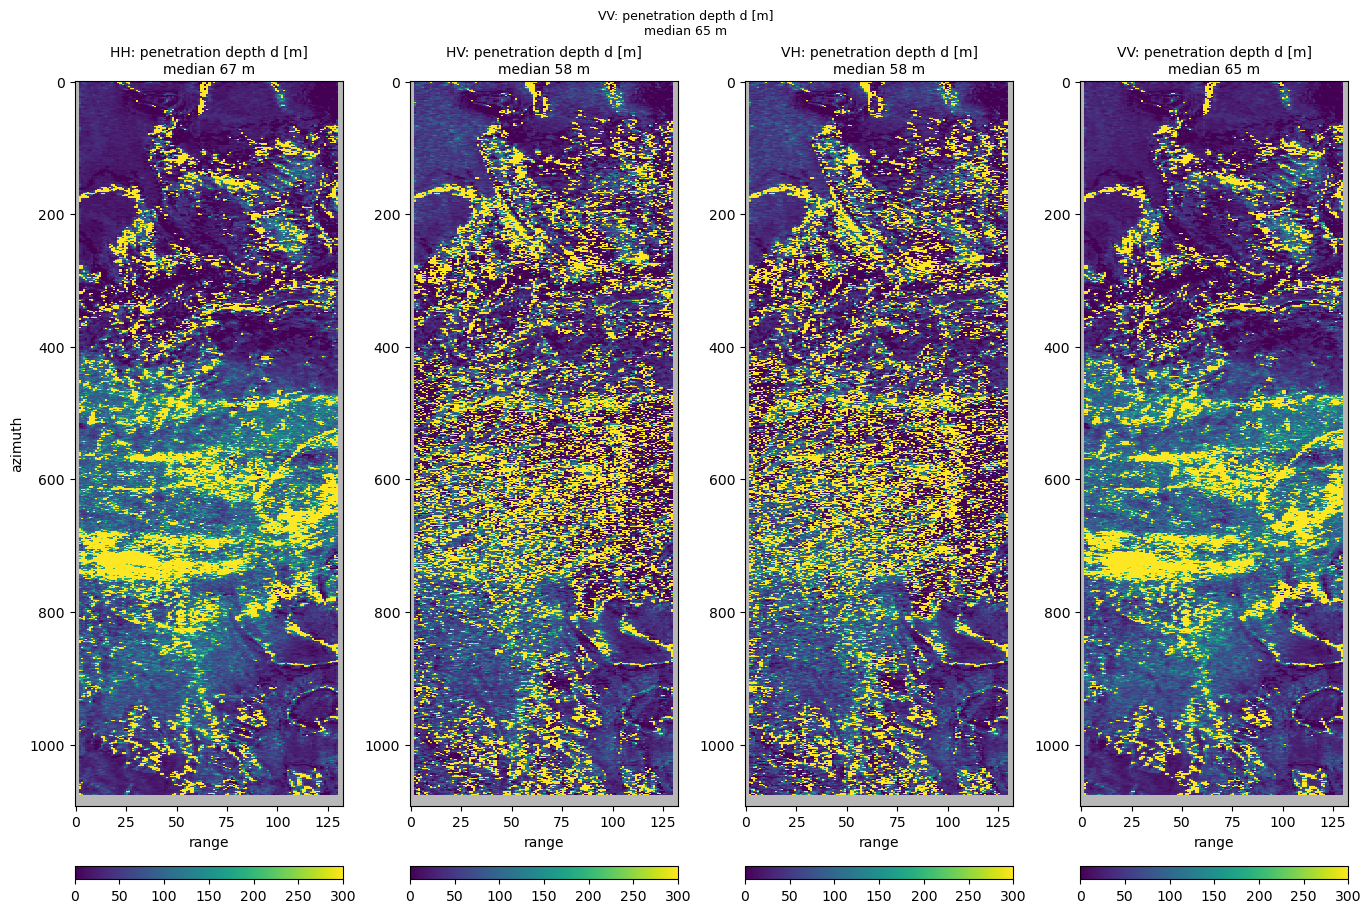

  saved BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS_penetration.png


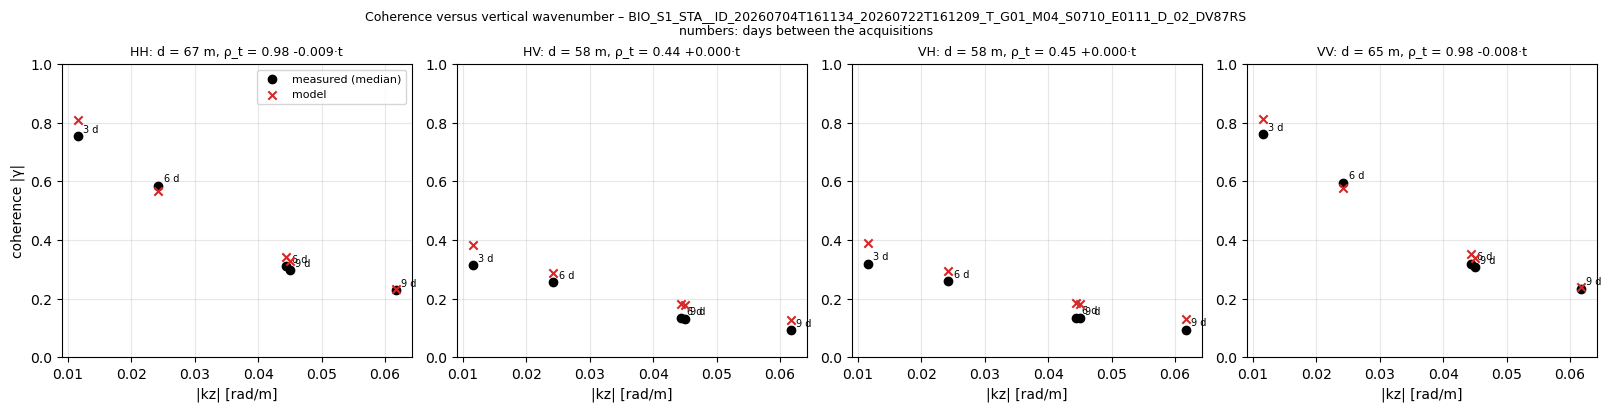

  saved BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS_coherence_fit.png


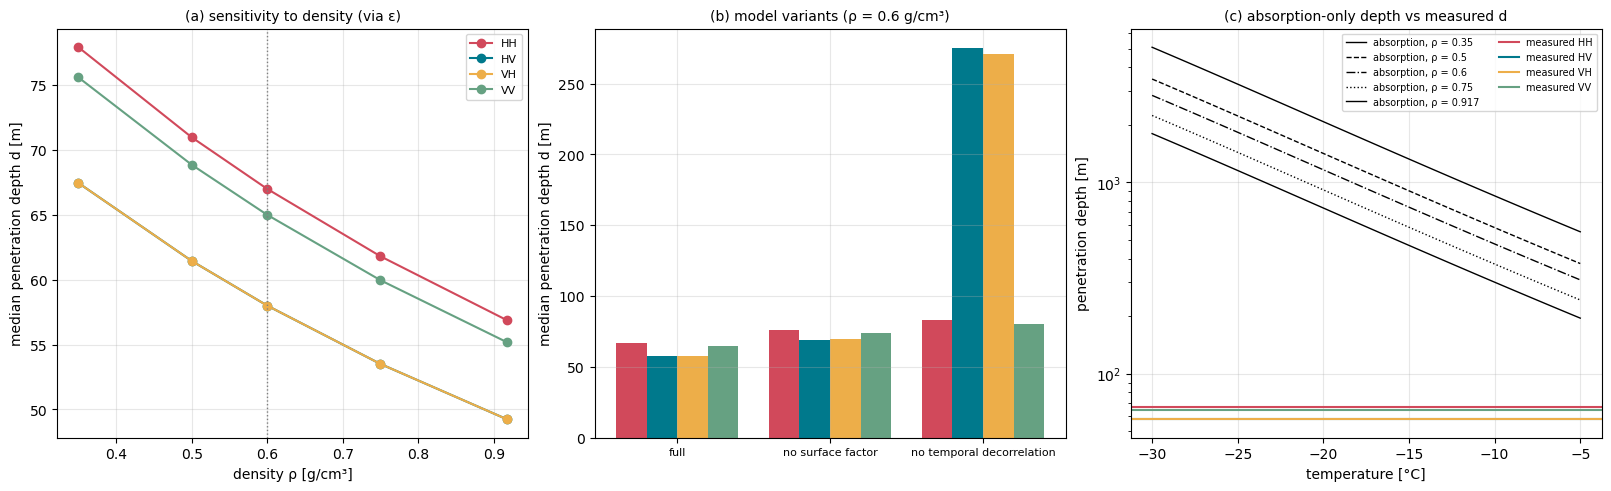

  saved BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS_sensitivity.png

  summary: /home/jovyan/idas_dump/test/Nivlisen/2026-10-15_150044_penetration/BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS/penetration/BIO_S1_STA__ID_20260704T161134_20260722T161209_T_G01_M04_S0710_E0111_D_02_DV87RS_penetration_summary.csv

Finished. Results in /home/jovyan/idas_dump/test/Nivlisen/2026-10-15_150044_penetration


In [4]:
run_dir = pu.new_run_folder(OUTPUT_DIR, "penetration", NEW_RUN_FOLDER, RUN_LABEL,
                            settings=dict(run_07_dir=RUN_07_DIR, stacks=STACKS, polarisations=POLARISATIONS,
                                          density=DENSITY, range_resolution_m=RANGE_RESOLUTION_M,
                                          surface_factor=SURFACE_FACTOR, temporal_model=TEMPORAL_MODEL,
                                          d_max_m=D_MAX_M, densities=DENSITIES, temperatures_c=TEMPERATURES_C))
pu.run_penetration_depth(stacks, RUN_07_DIR, run_dir, which_stacks=STACKS, pols=POLARISATIONS, density=DENSITY,
                         range_resolution_m=RANGE_RESOLUTION_M, surface_factor=SURFACE_FACTOR,
                         temporal=TEMPORAL_MODEL, d_max=D_MAX_M, densities=DENSITIES,
                         temperatures=TEMPERATURES_C, geotiff=SAVE_GEOTIFF, show=SHOW_FIGURES,
                         search_dir=OUTPUT_DIR)